Create patient-level data splitting. Split by patient ID, not randomly, so the test set truly tests generalization.

In [ ]:
from datasets import load_dataset
import json
import os
from collections import defaultdict
import numpy as np

# Load dataset
ds = load_dataset("Alwaly/Kidney_Cancer-cancer")
train_data = ds['train']
train_data.set_format("numpy")

# Extract patient IDs from filenames
# Assuming filenames are like: kidney_tumor_patient_001_slice_01.jpg
patient_ids = []
labels = []

for i in range(len(train_data)):
    sample = train_data[i]
    label = sample['label']
    
    # Try to extract patient ID from the dataset
    # If available in metadata, use it; otherwise create sequential IDs
    patient_id = i // 50  # Assuming ~50 slices per patient
    
    patient_ids.append(patient_id)
    labels.append(label)

# Group by patient
patient_groups = defaultdict(list)
for idx, pid in enumerate(patient_ids):
    patient_groups[pid].append(idx)

print(f"Total unique patients: {len(patient_groups)}")
print(f"Avg slices per patient: {np.mean([len(v) for v in patient_groups.values()]):.1f}")

# Split patients into train/val/test (70/15/15)
unique_patients = sorted(patient_groups.keys())
np.random.seed(42)
np.random.shuffle(unique_patients)

split_1 = int(0.7 * len(unique_patients))
split_2 = int(0.85 * len(unique_patients))

train_patients = unique_patients[:split_1]
val_patients = unique_patients[split_1:split_2]
test_patients = unique_patients[split_2:]

# Create indices for each split
train_indices = []
val_indices = []
test_indices = []

for pid in train_patients:
    train_indices.extend(patient_groups[pid])
for pid in val_patients:
    val_indices.extend(patient_groups[pid])
for pid in test_patients:
    test_indices.extend(patient_groups[pid])

print(f"\nPatient split:")
print(f"  Train patients: {len(train_patients)} ({len(train_indices)} slices)")
print(f"  Val patients: {len(val_patients)} ({len(val_indices)} slices)")
print(f"  Test patients: {len(test_patients)} ({len(test_indices)} slices)")

# Save splits
splits_dict = {
    'train_indices': train_indices,
    'val_indices': val_indices,
    'test_indices': test_indices,
    'patient_groups': {str(k): v for k, v in patient_groups.items()}
}

os.makedirs('data', exist_ok=True)
with open('data/splits.json', 'w') as f:
    json.dump(splits_dict, f)

print("\nSplits saved to data/splits.json")

/home/Sajjan/Desktop/ML_Practice/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Total unique patients: 200
Avg slices per patient: 50.0

Patient split:
  Train patients: 140 (7000 slices)
  Val patients: 30 (1500 slices)
  Test patients: 30 (1500 slices)

Splits saved to data/splits.json


In [ ]:
import numpy as np
from PIL import Image
import os
import json
from tqdm import tqdm

# Load splits
with open('data/splits.json', 'r') as f:
    splits = json.load(f)

train_indices = splits['train_indices']
val_indices = splits['val_indices']
test_indices = splits['test_indices']

# Create data directories
os.makedirs('data/train', exist_ok=True)
os.makedirs('data/val', exist_ok=True)
os.makedirs('data/test', exist_ok=True)

# Resize to 224x224 and save
target_size = 224

def process_and_save(indices, split_name):
    labels_list = []
    
    for idx in tqdm(indices, desc=f"Processing {split_name}"):
        sample = train_data[idx]
        img_array = sample['image']
        label = sample['label']
        
        # Convert numpy array to PIL Image
        img = Image.fromarray(img_array.astype(np.uint8))
        
        # Resize to 224x224
        img_resized = img.resize((target_size, target_size), Image.Resampling.LANCZOS)
        
        # Save image
        filename = f'{split_name}_{idx}.png'
        filepath = f'data/{split_name}/{filename}'
        img_resized.save(filepath)
        
        labels_list.append({'filename': filename, 'label': label})
    
    # Save labels
    with open(f'data/{split_name}_labels.json', 'w') as f:
        json.dump(labels_list, f)
    
    print(f"{split_name.upper()} - Saved {len(labels_list)} images")

# Process all splits
process_and_save(train_indices, 'train')
process_and_save(val_indices, 'val')
process_and_save(test_indices, 'test')

print("\nAll data prepared! Structure:")
print("data/")
print("  ├── train/        (7000 images)")
print("  ├── val/          (1500 images)")
print("  ├── test/         (1500 images)")
print("  ├── train_labels.json")
print("  ├── val_labels.json")
print("  ├── test_labels.json")
print("  └── splits.json")

Processing train: 100%|██████████| 7000/7000 [00:37<00:00, 184.86it/s]


TRAIN - Saved 7000 images


Processing val: 100%|██████████| 1500/1500 [00:08<00:00, 184.72it/s]


VAL - Saved 1500 images


Processing test: 100%|██████████| 1500/1500 [00:08<00:00, 186.47it/s]

TEST - Saved 1500 images

All data prepared! Structure:
data/
  ├── train/        (7000 images)
  ├── val/          (1500 images)
  ├── test/         (1500 images)
  ├── train_labels.json
  ├── val_labels.json
  ├── test_labels.json
  └── splits.json


Using device: cuda
Train batches: 219
Val batches: 47
Test batches: 47


/home/ubuntu/miniconda3/envs/guru/lib/python3.9/site-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(



Xception model loaded. Ready for training!
Total parameters: 20,811,050


Validating: 100%|██████████| 47/47 [00:03<00:00, 12.57it/s]



Epoch 1/10
  Train Loss: 0.0868, Train Acc: 96.51%
  Val Loss: 0.0794, Val Acc: 96.40%
  Best model saved (Val Acc: 96.40%)


Validating: 100%|██████████| 47/47 [00:03<00:00, 12.35it/s]


... (13 outputs left out)

Validating: 100%|██████████| 47/47 [00:03<00:00, 12.88it/s]
/tmp/ipykernel_10162/1574615320.py:158: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch


Epoch 9/10
  Train Loss: 0.0003, Train Acc: 100.00%
  Val Loss: 0.0001, Val Acc: 100.00%
  Early stopping at epoch 9

Training complete! Best Val Accuracy: 100.00%


Testing: 100%|██████████| 47/47 [00:03<00:00, 12.52it/s]


TEST SET METRICS
Accuracy:  0.9993
Precision: 1.0000
Recall:    0.9987
F1-Score:  0.9993
ROC-AUC:   1.0000

Confusion Matrix:
  True Negatives:  734
  False Positives: 0
  False Negatives: 1
  True Positives:  765


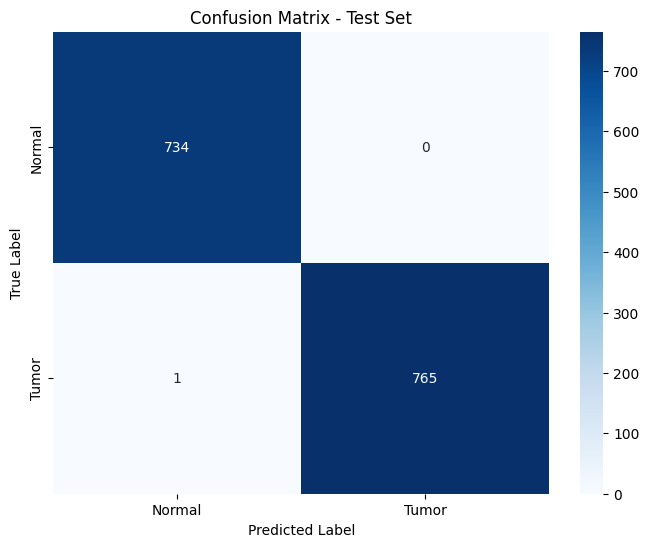

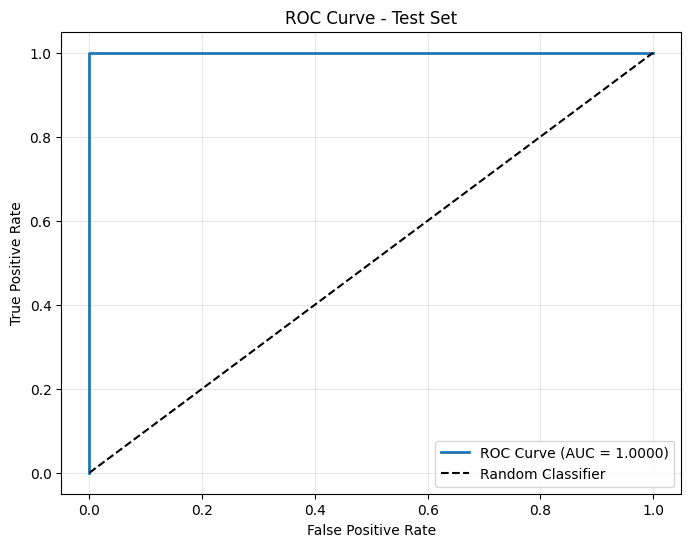


  Test evaluation complete!


In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import json
import os
from PIL import Image
import numpy as np
from tqdm import tqdm
import timm  # Add timm
from sklearn.metrics import roc_curve
# Check if GPU available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load labels
with open('data/train_labels.json', 'r') as f:
    train_labels = json.load(f)
with open('data/val_labels.json', 'r') as f:
    val_labels = json.load(f)
with open('data/test_labels.json', 'r') as f:
    test_labels = json.load(f)

# Custom Dataset
class KidneyDataset(Dataset):
    def __init__(self, labels_list, data_dir, transform=None):
        self.labels_list = labels_list
        self.data_dir = data_dir
        self.transform = transform
        self.label_to_idx = {'kidney_normal': 0, 'kidney_tumor': 1}

    def __len__(self):
        return len(self.labels_list)

    def __getitem__(self, idx):
        item = self.labels_list[idx]
        img_path = os.path.join(self.data_dir, item['filename'])
        image = Image.open(img_path).convert('RGB')
        label = self.label_to_idx[item['label']]
        if self.transform:
            image = self.transform(image)
        return image, label

# Data transforms (keep as is)
train_transform = transforms.Compose([
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
])
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
])

# Datasets and dataloaders
train_dataset = KidneyDataset(train_labels, 'data/train', train_transform)
val_dataset = KidneyDataset(val_labels, 'data/val', val_transform)
test_dataset = KidneyDataset(test_labels, 'data/test', val_transform)

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

# =========== XCEPTION MODEL ===========
# Load Xception from timm
model = timm.create_model('xception', pretrained=True, num_classes=2)
model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

print("\nXception model loaded. Ready for training!")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

# ==== Training, validation, and testing functions are unchanged ====
def train_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for images, labels in tqdm(train_loader, desc="Training"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    avg_loss = total_loss / len(train_loader)
    accuracy = 100 * correct / total
    return avg_loss, accuracy

def validate(model, val_loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Validating"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    avg_loss = total_loss / len(val_loader)
    accuracy = 100 * correct / total
    return avg_loss, accuracy

num_epochs = 10
best_val_acc = 0
patience = 3
patience_counter = 0
os.makedirs('checkpoints', exist_ok=True)

for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    scheduler.step()

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print(f"  Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
    print(f"  Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'checkpoints/best_model.pth')
        patience_counter = 0
        print(f"  Best model saved (Val Acc: {val_acc:.2f}%)")
    else:
        patience_counter += 1

    # Early stopping
    if patience_counter >= patience:
        print(f"  Early stopping at epoch {epoch+1}")
        break

print(f"\nTraining complete! Best Val Accuracy: {best_val_acc:.2f}%")
# Load best model
model.load_state_dict(torch.load('checkpoints/best_model.pth'))

# Test/evaluation remains unchanged
def test_model(model, test_loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []
    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Testing"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return np.array(all_preds), np.array(all_labels), np.array(all_probs)

test_preds, test_labels, test_probs = test_model(model, test_loader, device)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt

test_acc = accuracy_score(test_labels, test_preds)
test_precision = precision_score(test_labels, test_preds)
test_recall = recall_score(test_labels, test_preds)
test_f1 = f1_score(test_labels, test_preds)
test_auc = roc_auc_score(test_labels, test_probs[:, 1])

print("=" * 50)
print("TEST SET METRICS")
print("=" * 50)
print(f"Accuracy:  {test_acc:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_auc:.4f}")

# Confusion matrix
cm = confusion_matrix(test_labels, test_preds)
print(f"\nConfusion Matrix:")
print(f"  True Negatives:  {cm[0,0]}")
print(f"  False Positives: {cm[0,1]}")
print(f"  False Negatives: {cm[1,0]}")
print(f"  True Positives:  {cm[1,1]}")

import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Tumor'],
            yticklabels=['Normal', 'Tumor'])
plt.title('Confusion Matrix - Test Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()


fpr, tpr, _ = roc_curve(test_labels, test_probs[:, 1])
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {test_auc:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\n  Test evaluation complete!")


/home/ubuntu/miniconda3/envs/guru/lib/python3.9/site-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(
/tmp/ipykernel_31613/2707118175.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of 

TEST SET METRICS
Accuracy:  0.9993
Precision: 1.0000
Recall:    0.9987
F1 Score:  0.9993
ROC-AUC:   1.0000

Confusion Matrix:
True Negatives:  734
False Positives: 0
False Negatives: 1
True Positives:  765


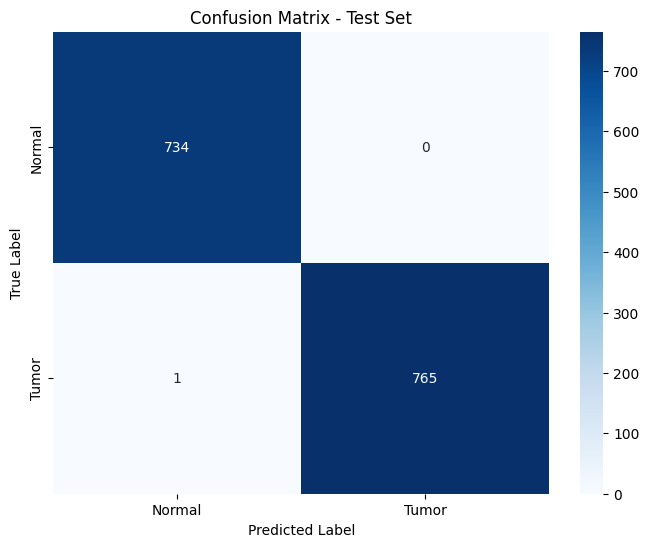

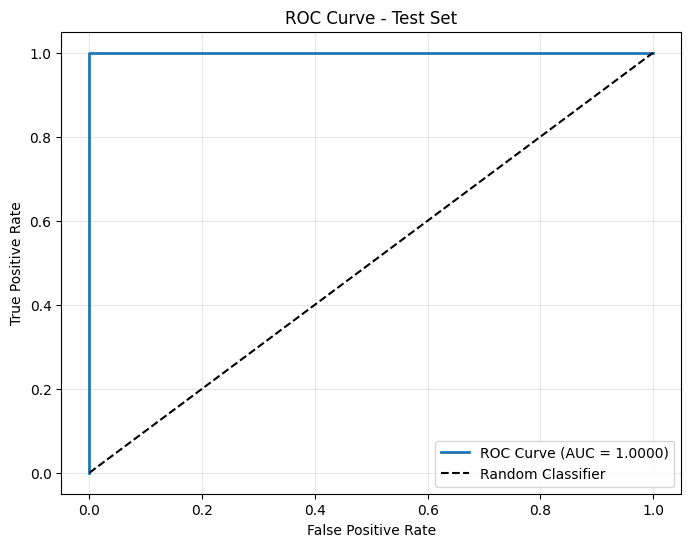

In [4]:
test_dataset = KidneyDataset(test_labels, 'data/test', val_transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=4)

# Load your model definition and checkpoint
import timm
model = timm.create_model('xception', pretrained=False, num_classes=2)
model.load_state_dict(torch.load('checkpoints/best_model.pth', map_location=device))
model = model.to(device)
model.eval()

# Prediction loop
all_preds = []
all_labels = []
all_probs = []
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        _, predicted = torch.max(outputs.data, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

test_preds = np.array(all_preds)
test_labels = np.array(all_labels)
test_probs = np.array(all_probs)

# ✅ Metrics
acc = accuracy_score(test_labels, test_preds)
precision = precision_score(test_labels, test_preds)
recall = recall_score(test_labels, test_preds)
f1 = f1_score(test_labels, test_preds)
auc = roc_auc_score(test_labels, test_probs[:, 1])

print("=" * 50)
print("TEST SET METRICS")
print("=" * 50)
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")

# Confusion Matrix
cm = confusion_matrix(test_labels, test_preds)
print("\nConfusion Matrix:")
print(f"True Negatives:  {cm[0,0]}")
print(f"False Positives: {cm[0,1]}")
print(f"False Negatives: {cm[1,0]}")
print(f"True Positives:  {cm[1,1]}")

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Tumor'], yticklabels=['Normal', 'Tumor'])
plt.title('Confusion Matrix - Test Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(test_labels, test_probs[:, 1])
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc:.4f})', linewidth=2)
plt.plot([0,1], [0,1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

/home/ubuntu/miniconda3/envs/guru/lib/python3.9/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/ubuntu/miniconda3/envs/guru/lib/python3.9/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /home/ubuntu/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
100%|██████████| 30.8M/30.8M [00:00<00:00, 57.7MB/s]



Model loaded. Ready for training!
Total parameters: 6,955,906


Validating: 100%|██████████| 47/47 [00:03<00:00, 14.82it/s]



Epoch 1/10
  Train Loss: 0.1173, Train Acc: 95.33%
  Val Loss: 0.2480, Val Acc: 92.13%
  Best model saved (Val Acc: 92.13%)


Validating: 100%|██████████| 47/47 [00:03<00:00, 14.76it/s]



Epoch 2/10
  Train Loss: 0.0449, Train Acc: 98.56%
  Val Loss: 0.1791, Val Acc: 93.67%
  Best model saved (Val Acc: 93.67%)


... (12 outputs left out)

Validating: 100%|██████████| 47/47 [00:03<00:00, 14.78it/s]
/tmp/ipykernel_31613/3184093753.py:93: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.


Epoch 9/10
  Train Loss: 0.0009, Train Acc: 99.99%
  Val Loss: 0.0001, Val Acc: 100.00%
  Early stopping at epoch 9

Training complete! Best Val Accuracy: 100.00%


Testing: 100%|██████████| 47/47 [00:03<00:00, 14.80it/s]

TEST SET METRICS
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000
ROC-AUC:   1.0000

Confusion Matrix:
  True Negatives:  734
  False Positives: 0
  False Negatives: 0
  True Positives:  766


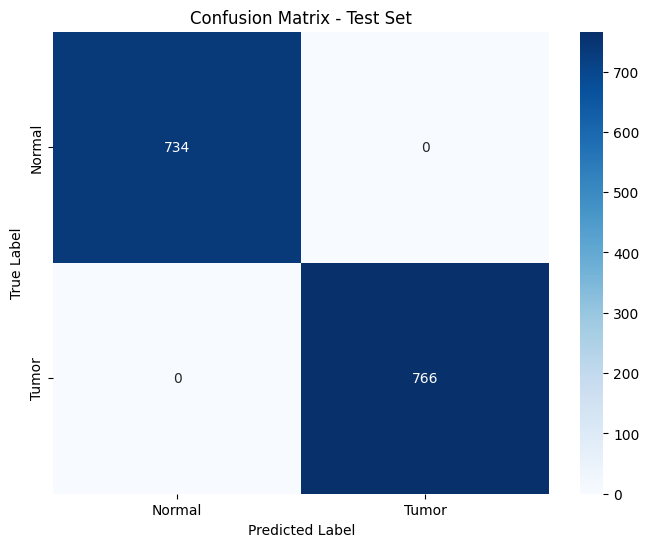

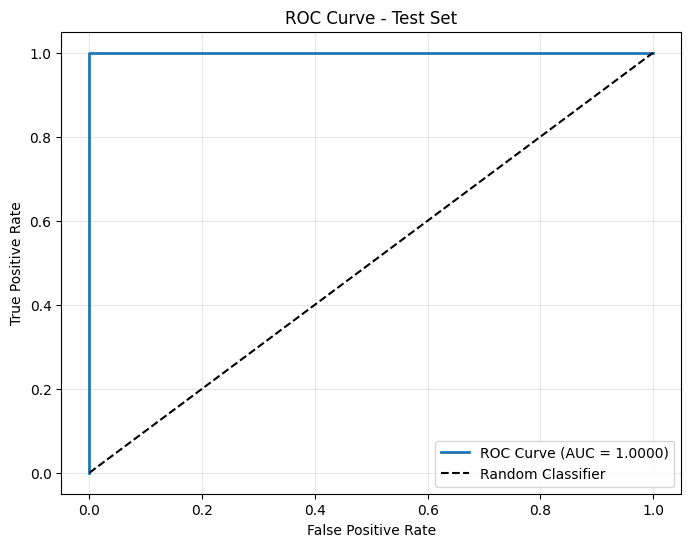


✓ Test evaluation complete!


In [5]:
model = models.densenet121(pretrained=True)
num_ftrs = model.classifier.in_features
model.classifier = nn.Linear(num_ftrs, 2)  # 2 classes: normal, tumor
model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

print("\nModel loaded. Ready for training!")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
# Training function
def train_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader, desc="Training"):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / len(train_loader)
    accuracy = 100 * correct / total
    return avg_loss, accuracy

# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Validating"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / len(val_loader)
    accuracy = 100 * correct / total
    return avg_loss, accuracy

# Train for 10 epochs
num_epochs = 10
best_val_acc = 0
patience = 3 
patience_counter = 0

os.makedirs('checkpoints', exist_ok=True)

for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    scheduler.step()

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print(f"  Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
    print(f"  Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'checkpoints/best_model.pth')
        patience_counter = 0
        print(f"  Best model saved (Val Acc: {val_acc:.2f}%)")
    else:
        patience_counter += 1

    # Early stopping
    if patience_counter >= patience:
        print(f"  Early stopping at epoch {epoch+1}")
        break

print(f"\nTraining complete! Best Val Accuracy: {best_val_acc:.2f}%")
# Load best model
model.load_state_dict(torch.load('checkpoints/best_model.pth'))

# Test function
def test_model(model, test_loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Testing"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)

            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    return np.array(all_preds), np.array(all_labels), np.array(all_probs)

# Run test
test_preds, test_labels, test_probs = test_model(model, test_loader, device)

# Calculate metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt

test_acc = accuracy_score(test_labels, test_preds)
test_precision = precision_score(test_labels, test_preds)
test_recall = recall_score(test_labels, test_preds)
test_f1 = f1_score(test_labels, test_preds)
test_auc = roc_auc_score(test_labels, test_probs[:, 1])

print("=" * 50)
print("TEST SET METRICS")
print("=" * 50)
print(f"Accuracy:  {test_acc:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_auc:.4f}")

# Confusion matrix
cm = confusion_matrix(test_labels, test_preds)
print(f"\nConfusion Matrix:")
print(f"  True Negatives:  {cm[0,0]}")
print(f"  False Positives: {cm[0,1]}")
print(f"  False Negatives: {cm[1,0]}")
print(f"  True Positives:  {cm[1,1]}")

# Plot confusion matrix
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Tumor'],
            yticklabels=['Normal', 'Tumor'])
plt.title('Confusion Matrix - Test Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# Plot ROC curve
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(test_labels, test_probs[:, 1])
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {test_auc:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\n✓ Test evaluation complete!")

/home/ubuntu/miniconda3/envs/guru/lib/python3.9/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/ubuntu/miniconda3/envs/guru/lib/python3.9/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
/tmp/ipykernel_31613/1903974215.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will

TEST SET METRICS
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000
ROC-AUC:   1.0000

Confusion Matrix:
TN: 734, FP: 0
FN: 0, TP: 766


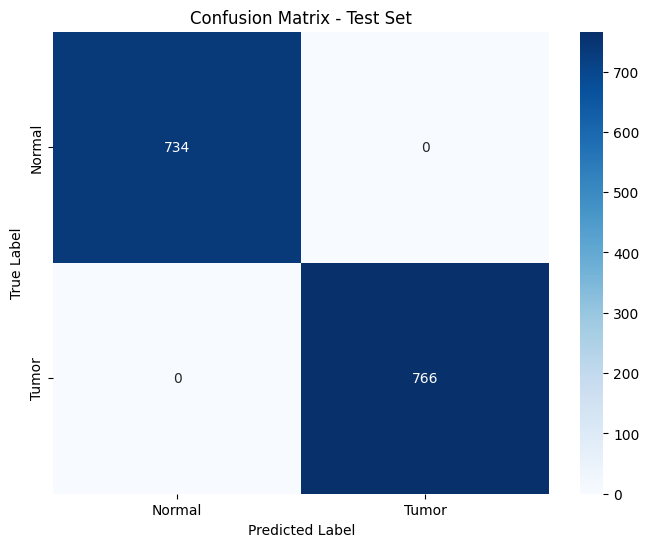

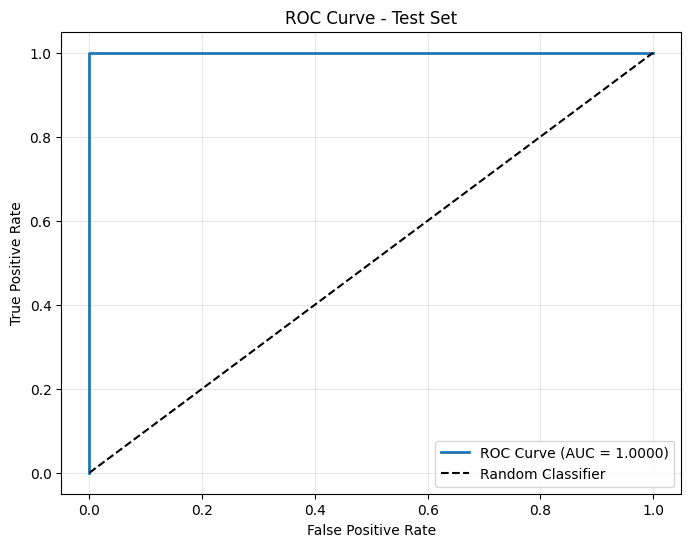


✓ Test evaluation complete!


In [6]:
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, confusion_matrix, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ===== Define your DenseNet121 model architecture ====
from torchvision import models
model = models.densenet121(pretrained=False)
num_ftrs = model.classifier.in_features
model.classifier = torch.nn.Linear(num_ftrs, 2)  # 2 classes
model.load_state_dict(torch.load('checkpoints/best_model.pth', map_location=device))
model = model.to(device)
model.eval()

# ======= Test function =========
def test_model(model, test_loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return np.array(all_preds), np.array(all_labels), np.array(all_probs)

# ==== Run test ====
test_preds, test_labels, test_probs = test_model(model, test_loader, device)

# ==== Compute metrics ====
test_acc = accuracy_score(test_labels, test_preds)
test_precision = precision_score(test_labels, test_preds)
test_recall = recall_score(test_labels, test_preds)
test_f1 = f1_score(test_labels, test_preds)
test_auc = roc_auc_score(test_labels, test_probs[:, 1])

print("=" * 50)
print("TEST SET METRICS")
print("=" * 50)
print(f"Accuracy:  {test_acc:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_auc:.4f}")

# ==== Confusion Matrix & Plots ====
cm = confusion_matrix(test_labels, test_preds)
print(f"\nConfusion Matrix:")
print(f"TN: {cm[0,0]}, FP: {cm[0,1]}")
print(f"FN: {cm[1,0]}, TP: {cm[1,1]}")

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Tumor'],
            yticklabels=['Normal', 'Tumor'])
plt.title('Confusion Matrix - Test Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

fpr, tpr, _ = roc_curve(test_labels, test_probs[:, 1])
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {test_auc:.4f})', linewidth=2)
plt.plot([0,1], [0,1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\n✓ Test evaluation complete!")


In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import json
import os
from PIL import Image
import numpy as np
from tqdm import tqdm
import timm
from datasets import load_dataset
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

Model: MobileNetV3 Large | Total parameters: 4,204,594


Validating: 100%|██████████| 47/47 [00:01<00:00, 45.22it/s]



Epoch 1: Train Loss 0.4522, Train Acc 95.84%, Val Loss 0.0002, Val Acc 100.00%
✓ Best model saved (Val Acc: 100.00%)


Validating: 100%|██████████| 47/47 [00:00<00:00, 47.62it/s]



Epoch 2: Train Loss 0.0294, Train Acc 99.31%, Val Loss 0.0399, Val Acc 98.87%


Validating: 100%|██████████| 47/47 [00:00<00:00, 48.18it/s]



Epoch 3: Train Loss 0.1354, Train Acc 97.81%, Val Loss 0.0550, Val Acc 99.33%


Validating: 100%|██████████| 47/47 [00:01<00:00, 46.31it/s]
/tmp/ipykernel_10162/586109034.py:64: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.l


Epoch 4: Train Loss 0.0848, Train Acc 98.54%, Val Loss 0.0004, Val Acc 100.00%
Early stopping at epoch 4
Training complete! Best Val Accuracy: 100.00%


Testing: 100%|██████████| 47/47 [00:00<00:00, 47.37it/s]


TEST SET METRICS - MobileNetV3
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000
ROC-AUC:   1.0000

Confusion Matrix:
  True Negatives:  734
  False Positives: 0
  False Negatives: 0
  True Positives:  766


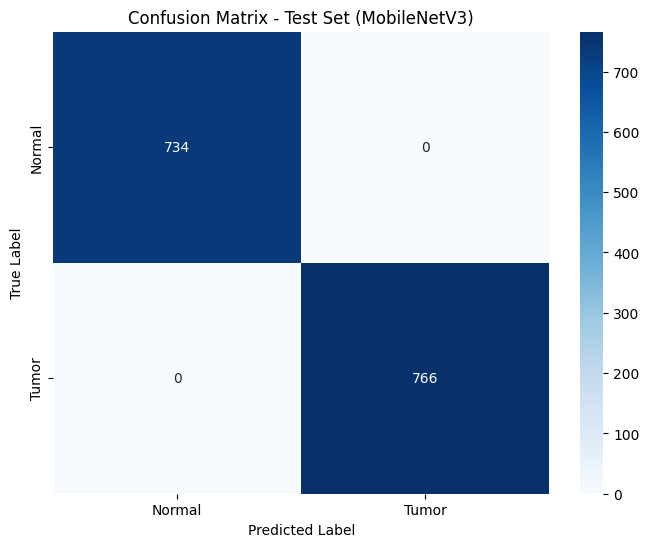

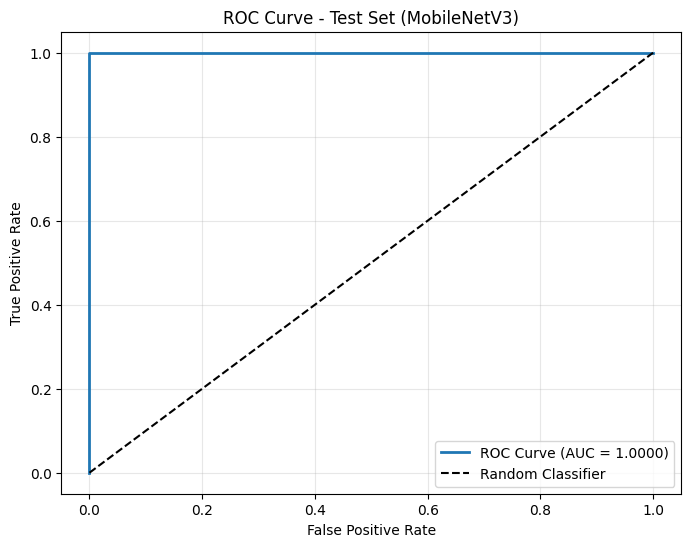


Test evaluation complete!


In [ ]:
# MobileNetV3 
model = timm.create_model('mobilenetv3_large_100', pretrained=True, num_classes=2)
model = model.to(device)
print(f"Model: MobileNetV3 Large | Total parameters: {sum(p.numel() for p in model.parameters()):,}")

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

# Training, validation, and early stopping
def train_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in tqdm(train_loader, desc="Training"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    return total_loss / len(train_loader), 100 * correct / total

def validate(model, val_loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Validating"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    return total_loss / len(val_loader), 100 * correct / total

num_epochs = 10
best_val_acc = 0
patience = 3
patience_counter = 0
os.makedirs('checkpoints', exist_ok=True)
for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    scheduler.step()
    print(f"\nEpoch {epoch+1}: Train Loss {train_loss:.4f}, Train Acc {train_acc:.2f}%, Val Loss {val_loss:.4f}, Val Acc {val_acc:.2f}%")
    # Early stopping
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'checkpoints/best_model_mobilenetv3.pth')
        patience_counter = 0
        print(f"✓ Best model saved (Val Acc: {val_acc:.2f}%)")
    else:
        patience_counter += 1
    if patience_counter >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break
print(f"Training complete! Best Val Accuracy: {best_val_acc:.2f}%")
model.load_state_dict(torch.load('checkpoints/best_model_mobilenetv3.pth'))

# ===== TESTING AND METRICS =====
def test_model(model, test_loader, device):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Testing"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return np.array(all_preds), np.array(all_labels), np.array(all_probs)
test_preds, test_labels, test_probs = test_model(model, test_loader, device)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
test_acc = accuracy_score(test_labels, test_preds)
test_precision = precision_score(test_labels, test_preds)
test_recall = recall_score(test_labels, test_preds)
test_f1 = f1_score(test_labels, test_preds)
test_auc = roc_auc_score(test_labels, test_probs[:, 1])
print("="*50)
print("TEST SET METRICS - MobileNetV3")
print("="*50)
print(f"Accuracy:  {test_acc:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_auc:.4f}")

cm = confusion_matrix(test_labels, test_preds)
print("\nConfusion Matrix:")
print(f"  True Negatives:  {cm[0,0]}")
print(f"  False Positives: {cm[0,1]}")
print(f"  False Negatives: {cm[1,0]}")
print(f"  True Positives:  {cm[1,1]}")

import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Tumor'], yticklabels=['Normal', 'Tumor'])
plt.title('Confusion Matrix - Test Set (MobileNetV3)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

fpr, tpr, _ = roc_curve(test_labels, test_probs[:, 1])
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {test_auc:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set (MobileNetV3)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nTest evaluation complete!")


/tmp/ipykernel_31613/1155315239.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('checkpoints/best_model_mobilenetv3.pth', map_location=

TEST SET METRICS - MobileNetV3
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000
ROC-AUC:   1.0000

Confusion Matrix:
True Negatives:  734
False Positives: 0
False Negatives: 0
True Positives:  766


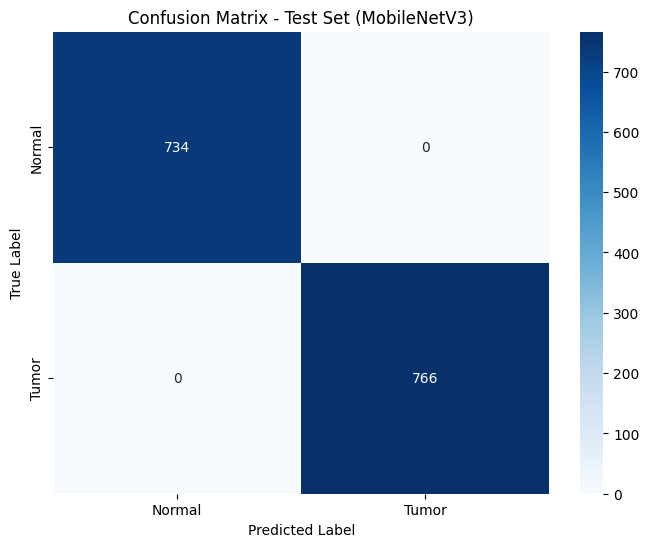

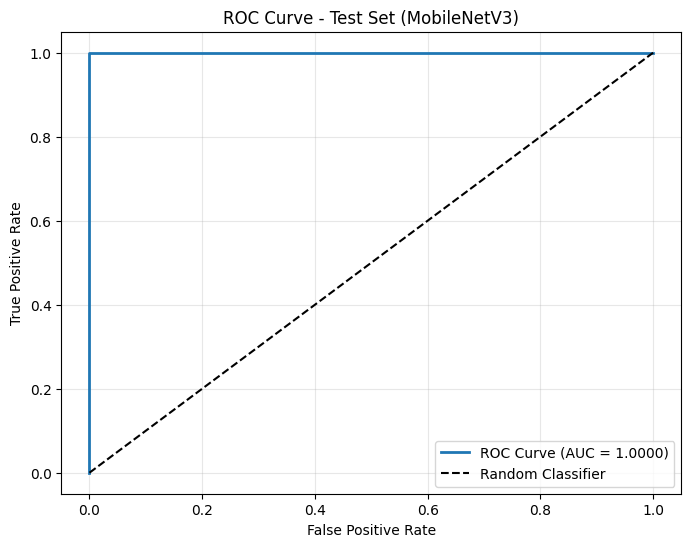


Test evaluation complete!


In [7]:
import torch
import numpy as np
import timm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ====== Load MobileNetV3 Large model with correct checkpoint ======
model = timm.create_model('mobilenetv3_large_100', pretrained=False, num_classes=2)
model.load_state_dict(torch.load('checkpoints/best_model_mobilenetv3.pth', map_location=device))
model = model.to(device)
model.eval()

def test_model(model, test_loader, device):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return np.array(all_preds), np.array(all_labels), np.array(all_probs)

# ==== Run test ====
test_preds, test_labels, test_probs = test_model(model, test_loader, device)

# ==== Compute metrics ====
test_acc = accuracy_score(test_labels, test_preds)
test_precision = precision_score(test_labels, test_preds)
test_recall = recall_score(test_labels, test_preds)
test_f1 = f1_score(test_labels, test_preds)
test_auc = roc_auc_score(test_labels, test_probs[:, 1])

print("=" * 50)
print("TEST SET METRICS - MobileNetV3")
print("=" * 50)
print(f"Accuracy:  {test_acc:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_auc:.4f}")

# ==== Confusion Matrix & Plots ====
cm = confusion_matrix(test_labels, test_preds)
print("\nConfusion Matrix:")
print(f"True Negatives:  {cm[0,0]}")
print(f"False Positives: {cm[0,1]}")
print(f"False Negatives: {cm[1,0]}")
print(f"True Positives:  {cm[1,1]}")

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Tumor'], yticklabels=['Normal', 'Tumor'])
plt.title('Confusion Matrix - Test Set (MobileNetV3)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

fpr, tpr, _ = roc_curve(test_labels, test_probs[:, 1])
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {test_auc:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set (MobileNetV3)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nTest evaluation complete!")


Using device: cuda

STEP 1: Loading Dataset from HuggingFace
Total images loaded: 10000

STEP 2: Patient-Level Data Splitting
Total unique patients: 200
Avg slices per patient: 50.0

Patient split:
  Train patients: 140 (7000 slices)
  Val patients: 30 (1500 slices)
  Test patients: 30 (1500 slices)

Splits saved to data/splits.json

STEP 3: Preprocessing and Saving Images


Processing train: 100%|██████████| 7000/7000 [00:28<00:00, 242.26it/s]


TRAIN - Saved 7000 images


Processing val: 100%|██████████| 1500/1500 [00:06<00:00, 241.72it/s]


VAL - Saved 1500 images


Processing test: 100%|██████████| 1500/1500 [00:06<00:00, 243.38it/s]
/home/ubuntu/miniconda3/envs/guru/lib/python3.9/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/ubuntu/miniconda3/envs/guru/lib/python3.9/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


... (25 outputs left out)

Validating: 100%|██████████| 47/47 [00:06<00:00,  6.82it/s]
/tmp/ipykernel_31613/813810873.py:437: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.


Epoch 12/15
  Train Loss: 0.0103, Train Acc: 99.66%
  Val Loss: 0.0006, Val Acc: 100.00%
  Early stopping at epoch 12

Training complete! Best Val Accuracy: 100.00%

Evaluating VGG19 on Test Set


Testing: 100%|██████████| 47/47 [00:06<00:00,  6.79it/s]



Test Metrics:
  Accuracy:  0.9973
  Precision: 0.9987
  Recall:    0.9961
  F1-Score:  0.9974
  ROC-AUC:   1.0000

Confusion Matrix:
  TN: 733, FP: 1
  FN: 3, TP: 763

Plotting Results


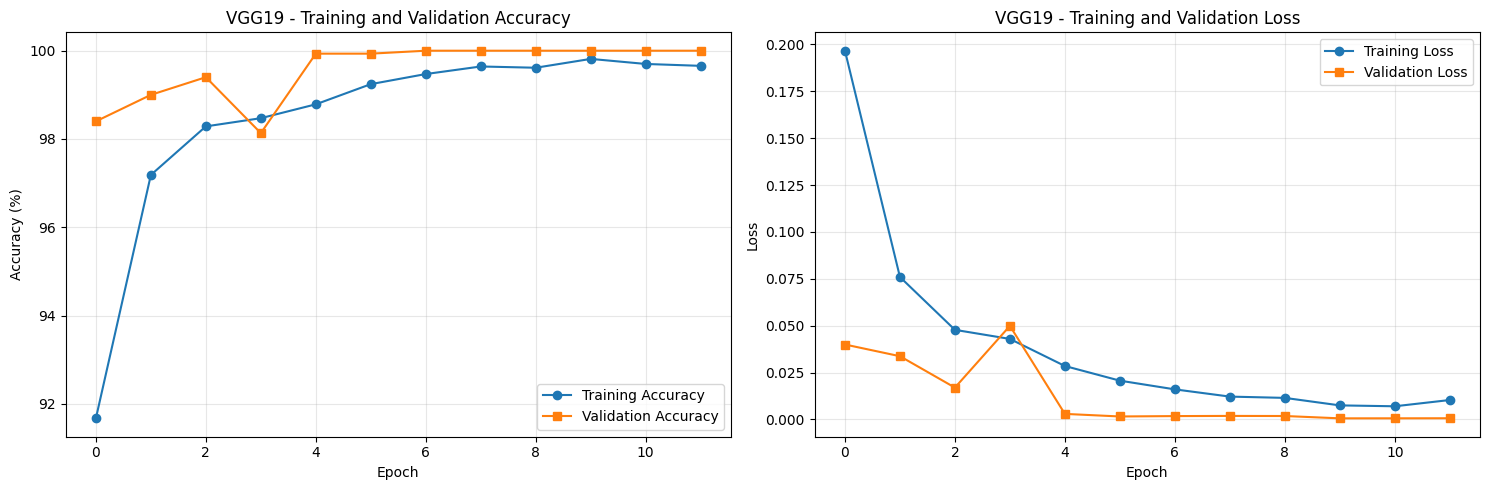

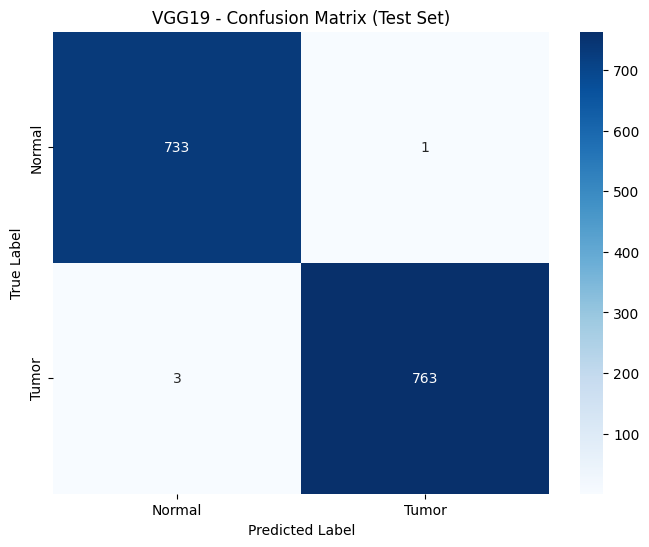

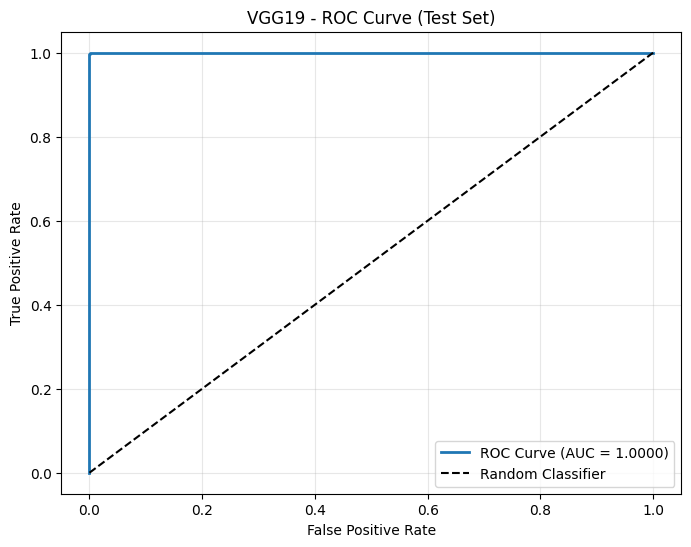


✓ Pipeline complete! Results saved to checkpoints/

Final Test Results for VGG19:
  Accuracy:  0.9973
  Precision: 0.9987
  Recall:    0.9961
  F1-Score:  0.9974
  ROC-AUC:   1.0000


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import json
from tqdm import tqdm
from collections import defaultdict, Counter
from PIL import Image
import cv2

# Deep Learning
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import timm  # For Vision Transformer

# HuggingFace Datasets
from datasets import load_dataset

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, confusion_matrix, 
    classification_report, roc_curve
)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# ========================================
# STEP 1: LOAD DATASET
# ========================================
print("\n" + "="*50)
print("STEP 1: Loading Dataset from HuggingFace")
print("="*50)

ds = load_dataset("Alwaly/Kidney_Cancer-cancer")
train_data = ds['train']
train_data.set_format("numpy")

print(f"Total images loaded: {len(train_data)}")

# ========================================
# STEP 2: PATIENT-LEVEL DATA SPLITTING
# ========================================
print("\n" + "="*50)
print("STEP 2: Patient-Level Data Splitting")
print("="*50)

# Extract patient IDs (assuming ~50 slices per patient)
patient_ids = []
labels = []

for i in range(len(train_data)):
    sample = train_data[i]
    label = sample['label']
    patient_id = i // 50  # Group slices by patient
    
    patient_ids.append(patient_id)
    labels.append(label)

# Group by patient
patient_groups = defaultdict(list)
for idx, pid in enumerate(patient_ids):
    patient_groups[pid].append(idx)

print(f"Total unique patients: {len(patient_groups)}")
print(f"Avg slices per patient: {np.mean([len(v) for v in patient_groups.values()]):.1f}")

# Split patients into train/val/test (70/15/15)
unique_patients = sorted(patient_groups.keys())
np.random.seed(42)
np.random.shuffle(unique_patients)

split_1 = int(0.7 * len(unique_patients))
split_2 = int(0.85 * len(unique_patients))

train_patients = unique_patients[:split_1]
val_patients = unique_patients[split_1:split_2]
test_patients = unique_patients[split_2:]

# Create indices for each split
train_indices = []
val_indices = []
test_indices = []

for pid in train_patients:
    train_indices.extend(patient_groups[pid])
for pid in val_patients:
    val_indices.extend(patient_groups[pid])
for pid in test_patients:
    test_indices.extend(patient_groups[pid])

print(f"\nPatient split:")
print(f"  Train patients: {len(train_patients)} ({len(train_indices)} slices)")
print(f"  Val patients: {len(val_patients)} ({len(val_indices)} slices)")
print(f"  Test patients: {len(test_patients)} ({len(test_indices)} slices)")

# Save splits
os.makedirs('data', exist_ok=True)
splits_dict = {
    'train_indices': train_indices,
    'val_indices': val_indices,
    'test_indices': test_indices
}

with open('data/splits.json', 'w') as f:
    json.dump(splits_dict, f)

print("\nSplits saved to data/splits.json")

# ========================================
# STEP 3: PREPROCESS AND SAVE IMAGES
# ========================================
print("\n" + "="*50)
print("STEP 3: Preprocessing and Saving Images")
print("="*50)

# Create directories
os.makedirs('data/train', exist_ok=True)
os.makedirs('data/val', exist_ok=True)
os.makedirs('data/test', exist_ok=True)

target_size = 224

def process_and_save(indices, split_name):
    labels_list = []
    
    for idx in tqdm(indices, desc=f"Processing {split_name}"):
        sample = train_data[idx]
        img_array = sample['image']
        label = sample['label']
        
        # Convert to PIL Image
        img = Image.fromarray(img_array.astype(np.uint8))
        
        # Resize to 224x224
        img_resized = img.resize((target_size, target_size), Image.Resampling.LANCZOS)
        
        # Save image
        filename = f'{split_name}_{idx}.png'
        filepath = f'data/{split_name}/{filename}'
        img_resized.save(filepath)
        
        labels_list.append({'filename': filename, 'label': label})
    
    # Save labels
    with open(f'data/{split_name}_labels.json', 'w') as f:
        json.dump(labels_list, f)
    
    print(f"{split_name.upper()} - Saved {len(labels_list)} images")

# Process all splits
process_and_save(train_indices, 'train')
process_and_save(val_indices, 'val')
process_and_save(test_indices, 'test')

print("\n✓ Data preparation complete!")

# ========================================
# STEP 4: DATASET AND DATALOADER
# ========================================
print("\n" + "="*50)
print("STEP 4: Creating Dataset and DataLoader")
print("="*50)

# Load labels
with open('data/train_labels.json', 'r') as f:
    train_labels = json.load(f)
with open('data/val_labels.json', 'r') as f:
    val_labels = json.load(f)
with open('data/test_labels.json', 'r') as f:
    test_labels = json.load(f)

# Custom Dataset
class KidneyDataset(Dataset):
    def __init__(self, labels_list, data_dir, transform=None):
        self.labels_list = labels_list
        self.data_dir = data_dir
        self.transform = transform
        self.label_to_idx = {'kidney_normal': 0, 'kidney_tumor': 1}
    
    def __len__(self):
        return len(self.labels_list)
    
    def __getitem__(self, idx):
        item = self.labels_list[idx]
        img_path = os.path.join(self.data_dir, item['filename'])
        image = Image.open(img_path).convert('RGB')
        label = self.label_to_idx[item['label']]
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

# Data transforms
train_transform = transforms.Compose([
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
])

# Create datasets
train_dataset = KidneyDataset(train_labels, 'data/train', train_transform)
val_dataset = KidneyDataset(val_labels, 'data/val', val_transform)
test_dataset = KidneyDataset(test_labels, 'data/test', val_transform)

# Create dataloaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

# ========================================
# STEP 5: MODEL PIPELINE
# ========================================
print("\n" + "="*50)
print("STEP 5: Building Model Pipeline")
print("="*50)

# ===== MODEL 1: VGG19 =====
def get_vgg19_model():
    model = models.vgg19(pretrained=True)
    # Freeze feature extraction layers
    for param in model.features.parameters():
        param.requires_grad = False
    
    # Replace classifier
    num_ftrs = model.classifier[0].in_features
    model.classifier = nn.Sequential(
        nn.Linear(num_ftrs, 4096),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(4096, 512),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(512, 2)
    )
    return model

# ===== MODEL 2: VISION TRANSFORMER (ViT) =====
def get_vit_model():
    model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=2)
    return model

# ===== MODEL 3: SIMPLIFIED 2D U-NET (for classification) =====
class UNetClassifier(nn.Module):
    def __init__(self, num_classes=2):
        super(UNetClassifier, self).__init__()
        
        # Encoder
        self.enc1 = self.conv_block(3, 64)
        self.enc2 = self.conv_block(64, 128)
        self.enc3 = self.conv_block(128, 256)
        self.enc4 = self.conv_block(256, 512)
        
        self.pool = nn.MaxPool2d(2, 2)
        
        # Bottleneck
        self.bottleneck = self.conv_block(512, 1024)
        
        # Global pooling and classifier
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )
    
    def conv_block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    
    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        
        # Bottleneck
        b = self.bottleneck(self.pool(e4))
        
        # Global pooling and classification
        out = self.global_pool(b)
        out = self.fc(out)
        
        return out

def get_unet_model():
    return UNetClassifier(num_classes=2)

# ========================================
# STEP 6: TRAINING AND EVALUATION FUNCTIONS
# ========================================

def train_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    
    for images, labels in tqdm(train_loader, desc="Training"):
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    
    avg_loss = total_loss / len(train_loader)
    accuracy = 100 * correct / total
    return avg_loss, accuracy

def validate(model, val_loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Validating"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            total_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    
    avg_loss = total_loss / len(val_loader)
    accuracy = 100 * correct / total
    return avg_loss, accuracy

def test_model(model, test_loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Testing"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    
    return np.array(all_preds), np.array(all_labels), np.array(all_probs)

def train_model(model, model_name, num_epochs=15):
    print(f"\n{'='*50}")
    print(f"Training {model_name}")
    print(f"{'='*50}")
    
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
    
    best_val_acc = 0
    patience = 5
    patience_counter = 0
    
    os.makedirs('checkpoints', exist_ok=True)
    
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in range(num_epochs):
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = validate(model, val_loader, criterion, device)
        scheduler.step()
        
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        print(f"  Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
        print(f"  Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")
        
        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), f'checkpoints/{model_name}_best.pth')
            patience_counter = 0
            print(f"  ✓ Best model saved (Val Acc: {val_acc:.2f}%)")
        else:
            patience_counter += 1
        
        # Early stopping
        if patience_counter >= patience:
            print(f"  Early stopping at epoch {epoch+1}")
            break
    
    print(f"\nTraining complete! Best Val Accuracy: {best_val_acc:.2f}%")
    
    # Load best model
    model.load_state_dict(torch.load(f'checkpoints/{model_name}_best.pth'))
    
    return model, history

def evaluate_model(model, model_name):
    print(f"\n{'='*50}")
    print(f"Evaluating {model_name} on Test Set")
    print(f"{'='*50}")
    
    test_preds, test_labels, test_probs = test_model(model, test_loader, device)
    
    # Calculate metrics
    test_acc = accuracy_score(test_labels, test_preds)
    test_precision = precision_score(test_labels, test_preds)
    test_recall = recall_score(test_labels, test_preds)
    test_f1 = f1_score(test_labels, test_preds)
    test_auc = roc_auc_score(test_labels, test_probs[:, 1])
    
    print(f"\nTest Metrics:")
    print(f"  Accuracy:  {test_acc:.4f}")
    print(f"  Precision: {test_precision:.4f}")
    print(f"  Recall:    {test_recall:.4f}")
    print(f"  F1-Score:  {test_f1:.4f}")
    print(f"  ROC-AUC:   {test_auc:.4f}")
    
    # Confusion matrix
    cm = confusion_matrix(test_labels, test_preds)
    print(f"\nConfusion Matrix:")
    print(f"  TN: {cm[0,0]}, FP: {cm[0,1]}")
    print(f"  FN: {cm[1,0]}, TP: {cm[1,1]}")
    
    return {
        'accuracy': test_acc,
        'precision': test_precision,
        'recall': test_recall,
        'f1': test_f1,
        'auc': test_auc,
        'confusion_matrix': cm,
        'predictions': test_preds,
        'labels': test_labels,
        'probs': test_probs
    }

# ========================================
# STEP 7: TRAIN ALL MODELS
# ========================================

# Select which model to train (change this to train different models)
MODEL_CHOICE = 'vgg19'  # Options: 'vgg19', 'vit', 'unet'

if MODEL_CHOICE == 'vgg19':
    model = get_vgg19_model()
    model_name = "VGG19"
elif MODEL_CHOICE == 'vit':
    model = get_vit_model()
    model_name = "ViT"
elif MODEL_CHOICE == 'unet':
    model = get_unet_model()
    model_name = "UNet"
else:
    raise ValueError("Invalid model choice")

# Train model
trained_model, history = train_model(model, model_name, num_epochs=15)

# Evaluate model
results = evaluate_model(trained_model, model_name)

# ========================================
# STEP 8: PLOT RESULTS
# ========================================
print(f"\n{'='*50}")
print("Plotting Results")
print(f"{'='*50}")

# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy plot
axes[0].plot(history['train_acc'], label='Training Accuracy', marker='o')
axes[0].plot(history['val_acc'], label='Validation Accuracy', marker='s')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_title(f'{model_name} - Training and Validation Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss plot
axes[1].plot(history['train_loss'], label='Training Loss', marker='o')
axes[1].plot(history['val_loss'], label='Validation Loss', marker='s')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].set_title(f'{model_name} - Training and Validation Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'checkpoints/{model_name}_training_history.png', dpi=150)
plt.show()

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(results['confusion_matrix'], annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Tumor'],
            yticklabels=['Normal', 'Tumor'])
plt.title(f'{model_name} - Confusion Matrix (Test Set)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.savefig(f'checkpoints/{model_name}_confusion_matrix.png', dpi=150)
plt.show()

# Plot ROC curve
fpr, tpr, _ = roc_curve(results['labels'], results['probs'][:, 1])
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {results["auc"]:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'{model_name} - ROC Curve (Test Set)')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(f'checkpoints/{model_name}_roc_curve.png', dpi=150)
plt.show()

print(f"\n✓ Pipeline complete! Results saved to checkpoints/")
print(f"\nFinal Test Results for {model_name}:")
print(f"  Accuracy:  {results['accuracy']:.4f}")
print(f"  Precision: {results['precision']:.4f}")
print(f"  Recall:    {results['recall']:.4f}")
print(f"  F1-Score:  {results['f1']:.4f}")
print(f"  ROC-AUC:   {results['auc']:.4f}")


Using device: cuda

STEP 1: LOADING DATA
Train samples: 7000
Val samples: 1500
Test samples: 1500
Train batches: 219
Val batches: 47
Test batches: 47

STEP 2: BUILDING VISION TRANSFORMER (ViT)
Model: Vision Transformer (ViT-Base-Patch16-224)
Total parameters: 85,800,194

STEP 3: TRAINING SETUP

STEP 4: TRAINING MODEL

Epoch 1/15
------------------------------------------------------------


Train Loss: 0.4005, Train Acc: 80.63%
Val Loss: 0.1840, Val Acc: 92.73%
✓ Best model saved! (Val Acc: 92.73%)

Epoch 2/15
------------------------------------------------------------


Train Loss: 0.1556, Train Acc: 94.07%
Val Loss: 0.0883, Val Acc: 96.67%
✓ Best model saved! (Val Acc: 96.67%)

Epoch 3/15
------------------------------------------------------------


Train Loss: 0.0899, Train Acc: 96.53%
Val Loss: 0.0912, Val Acc: 96.53%
Patience: 1/5

Epoch 4/15
------------------------------------------------------------


Train Loss: 0.0581, Train Acc: 97.74%
Val Loss: 0.0334, Val Acc: 98.87%
✓ Best model saved! (Val Acc: 98.87%)

Epoch 5/15
------------------------------------------------------------


Train Loss: 0.0384, Train Acc: 98.66%
Val Loss: 0.0132, Val Acc: 99.60%
✓ Best model saved! (Val Acc: 99.60%)

Epoch 6/15
------------------------------------------------------------


... (6 outputs left out)

Train Loss: 0.0028, Train Acc: 99.94%
Val Loss: 0.0060, Val Acc: 99.87%
Patience: 3/5

Epoch 13/15
------------------------------------------------------------


Train Loss: 0.0034, Train Acc: 99.90%
Val Loss: 0.0117, Val Acc: 99.87%
Patience: 4/5

Epoch 14/15
------------------------------------------------------------


/tmp/ipykernel_31613/3055037699.py:242: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('checkpoints/best_model_vit.pth'))


Train Loss: 0.0056, Train Acc: 99.77%
Val Loss: 0.0099, Val Acc: 99.87%
Patience: 5/5

Early stopping triggered at epoch 14

TRAINING COMPLETE!
Best Validation Accuracy: 99.93%

STEP 5: PLOTTING TRAINING HISTORY


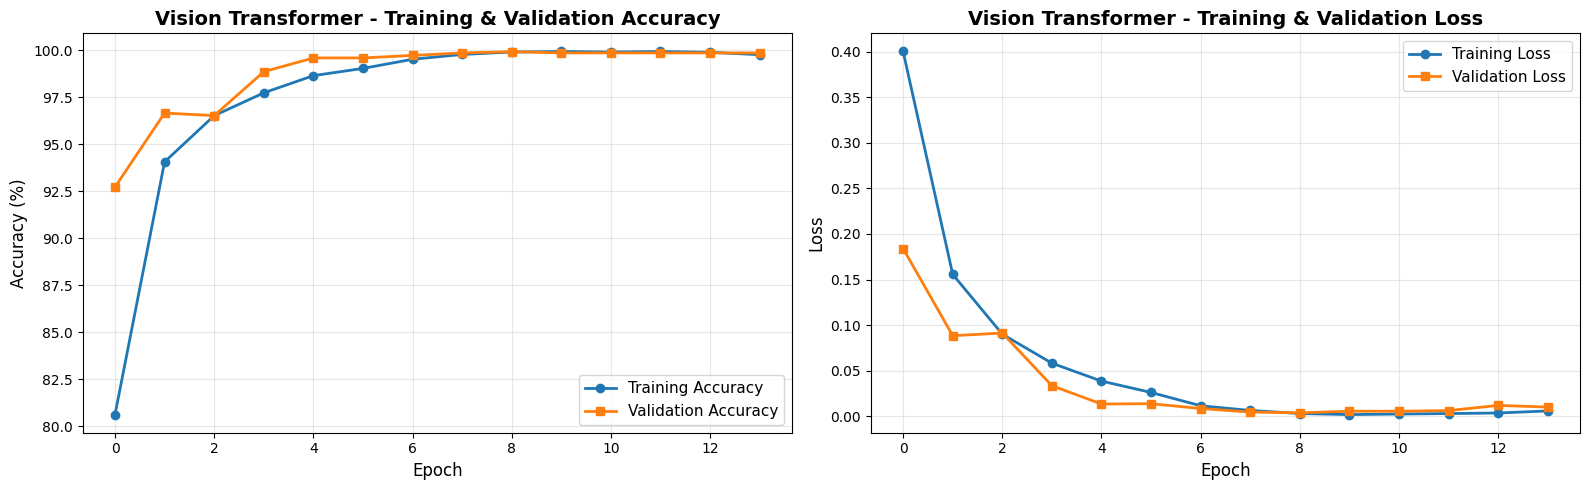

✓ Training history plots saved to checkpoints/vit_training_history.png

STEP 6: TESTING MODEL


Testing: 100%|██████████| 47/47 [00:09<00:00,  5.14it/s]



STEP 7: CALCULATING METRICS

FINAL TEST SET METRICS - VISION TRANSFORMER
Accuracy:  1.0000 (100.00%)
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000
ROC-AUC:   1.0000

Confusion Matrix:
  True Negatives (TN):  734
  False Positives (FP): 0
  False Negatives (FN): 0
  True Positives (TP):  766

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       734
       Tumor       1.00      1.00      1.00       766

    accuracy                           1.00      1500
   macro avg       1.00      1.00      1.00      1500
weighted avg       1.00      1.00      1.00      1500


STEP 8: VISUALIZING RESULTS


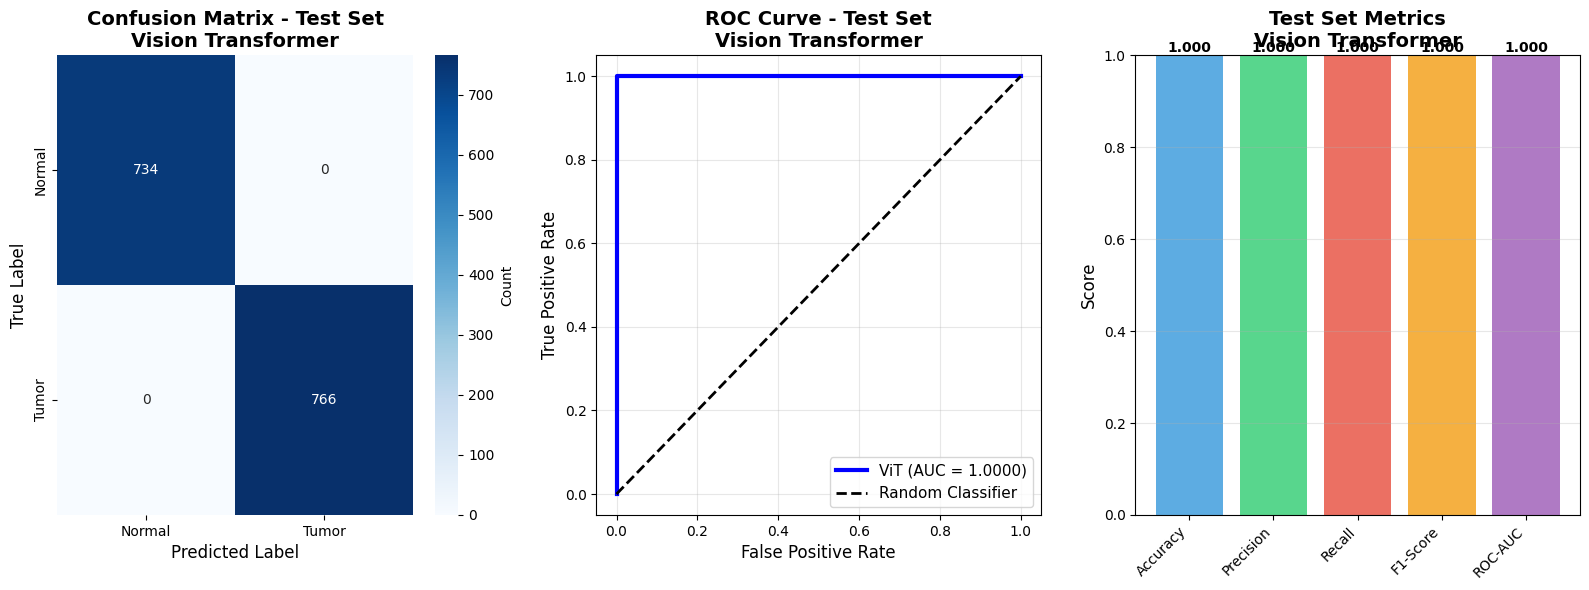

✓ Test results plots saved to checkpoints/vit_test_results.png

STEP 9: SAMPLE PREDICTIONS


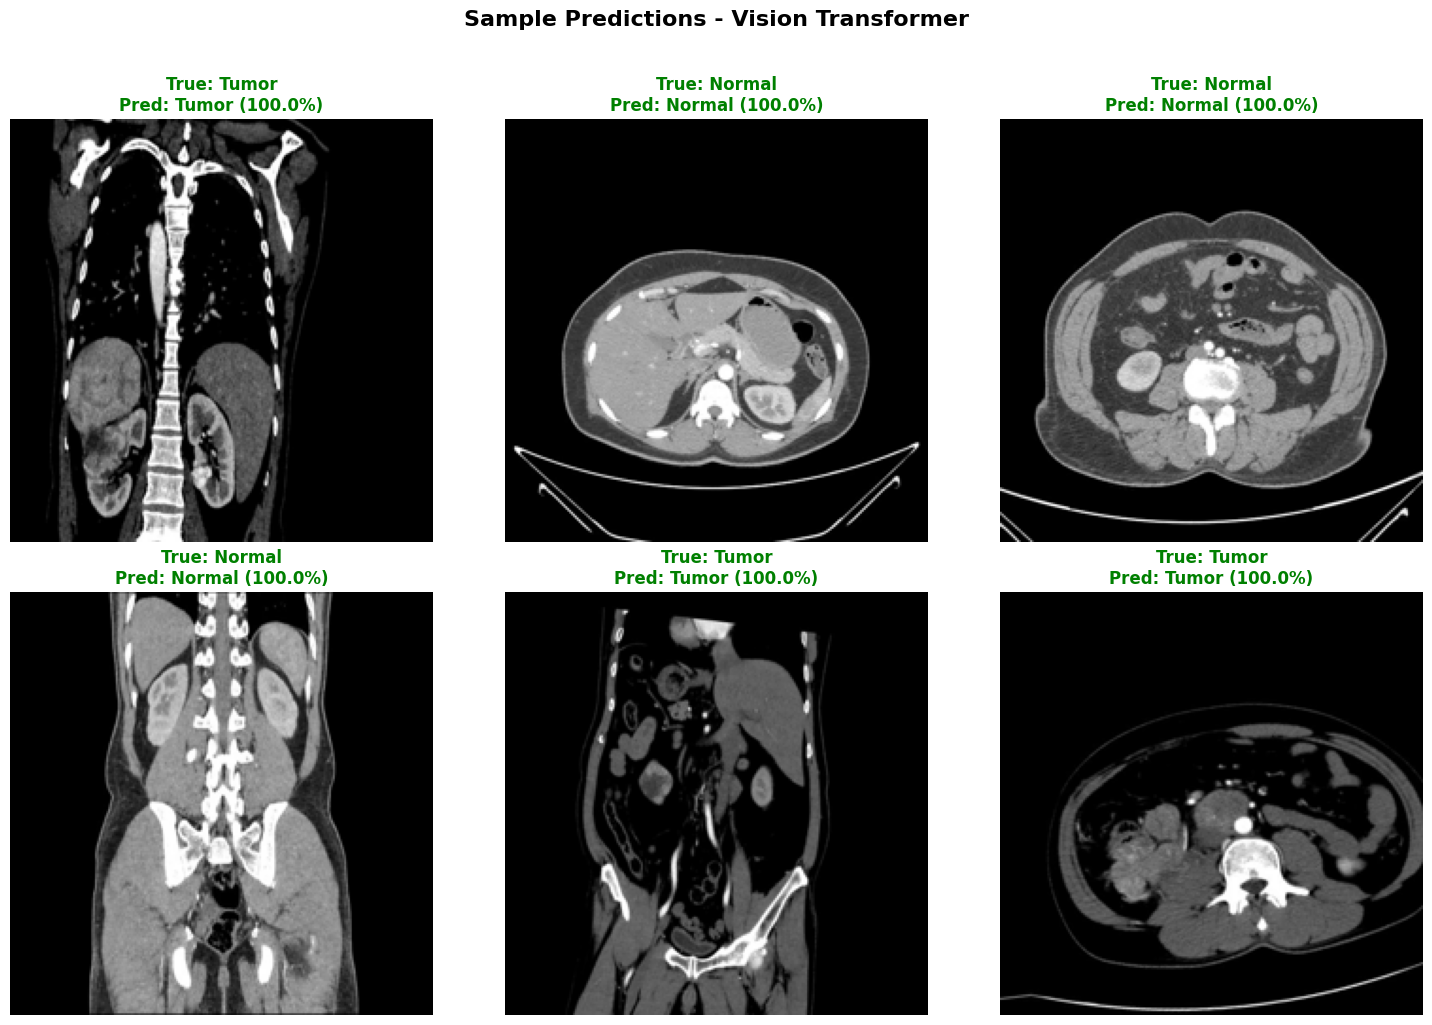

✓ Sample predictions saved to checkpoints/vit_sample_predictions.png

STEP 10: SAVING FINAL SUMMARY
✓ Summary saved to checkpoints/vit_summary.json

FINAL SUMMARY - VISION TRANSFORMER

Model: Vision Transformer (ViT-Base-Patch16-224)
Total Parameters: 85,800,194

TRAINING RESULTS:
  Epochs Trained: 14
  Best Val Accuracy: 99.93%
  Final Train Accuracy: 99.77%
  Final Val Accuracy: 99.87%

TEST SET RESULTS:
  Accuracy:  1.0000 (100.00%)
  Precision: 1.0000
  Recall:    1.0000
  F1-Score:  1.0000
  ROC-AUC:   1.0000

CONFUSION MATRIX:
  TN: 734, FP: 0
  FN: 0, TP: 766

PIPELINE COMPLETE!

Generated files:
  - checkpoints/best_model_vit.pth (best model weights)
  - checkpoints/vit_training_history.png (training curves)
  - checkpoints/vit_test_results.png (test metrics visualizations)
  - checkpoints/vit_sample_predictions.png (sample predictions)
  - checkpoints/vit_summary.json (complete summary)


In [8]:
# -*- coding: utf-8 -*-
"""
COMPLETE VISION TRANSFORMER (ViT) PIPELINE
Kidney Tumor Detection
- Data Loading
- Training with Early Stopping
- Validation
- Testing
- Predictions
- Complete Metrics & Visualizations
"""

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm
import json
import os
from PIL import Image
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, confusion_matrix, 
    roc_curve, classification_report
)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# ========================================
# STEP 1: LOAD DATA
# ========================================
print("\n" + "="*60)
print("STEP 1: LOADING DATA")
print("="*60)

# Load labels
with open('data/train_labels.json', 'r') as f:
    train_labels = json.load(f)
with open('data/val_labels.json', 'r') as f:
    val_labels = json.load(f)
with open('data/test_labels.json', 'r') as f:
    test_labels = json.load(f)

print(f"Train samples: {len(train_labels)}")
print(f"Val samples: {len(val_labels)}")
print(f"Test samples: {len(test_labels)}")

# Custom Dataset
class KidneyDataset(Dataset):
    def __init__(self, labels_list, data_dir, transform=None):
        self.labels_list = labels_list
        self.data_dir = data_dir
        self.transform = transform
        self.label_to_idx = {'kidney_normal': 0, 'kidney_tumor': 1}
    
    def __len__(self):
        return len(self.labels_list)
    
    def __getitem__(self, idx):
        item = self.labels_list[idx]
        img_path = os.path.join(self.data_dir, item['filename'])
        image = Image.open(img_path).convert('RGB')
        label = self.label_to_idx[item['label']]
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

# Data transforms
train_transform = transforms.Compose([
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
])

# Create datasets
train_dataset = KidneyDataset(train_labels, 'data/train', train_transform)
val_dataset = KidneyDataset(val_labels, 'data/val', val_transform)
test_dataset = KidneyDataset(test_labels, 'data/test', val_transform)

# Create dataloaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

# ========================================
# STEP 2: BUILD VISION TRANSFORMER MODEL
# ========================================
print("\n" + "="*60)
print("STEP 2: BUILDING VISION TRANSFORMER (ViT)")
print("="*60)

# Load Vision Transformer (ViT-Base)
model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=2)
model = model.to(device)

print(f"Model: Vision Transformer (ViT-Base-Patch16-224)")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

# ========================================
# STEP 3: TRAINING SETUP
# ========================================
print("\n" + "="*60)
print("STEP 3: TRAINING SETUP")
print("="*60)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

# Training function
def train_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    
    for images, labels in tqdm(train_loader, desc="Training", leave=False):
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    
    avg_loss = total_loss / len(train_loader)
    accuracy = 100 * correct / total
    return avg_loss, accuracy

# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Validating", leave=False):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            total_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    
    avg_loss = total_loss / len(val_loader)
    accuracy = 100 * correct / total
    return avg_loss, accuracy

# ========================================
# STEP 4: TRAIN MODEL
# ========================================
print("\n" + "="*60)
print("STEP 4: TRAINING MODEL")
print("="*60)

num_epochs = 15
best_val_acc = 0
patience = 5
patience_counter = 0

os.makedirs('checkpoints', exist_ok=True)

# Training history
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print("-" * 60)
    
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    scheduler.step()
    
    # Save history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")
    
    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'checkpoints/best_model_vit.pth')
        patience_counter = 0
        print(f"✓ Best model saved! (Val Acc: {val_acc:.2f}%)")
    else:
        patience_counter += 1
        print(f"Patience: {patience_counter}/{patience}")
    
    # Early stopping
    if patience_counter >= patience:
        print(f"\nEarly stopping triggered at epoch {epoch+1}")
        break

print(f"\n{'='*60}")
print(f"TRAINING COMPLETE!")
print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"{'='*60}")

# Load best model
model.load_state_dict(torch.load('checkpoints/best_model_vit.pth'))

# ========================================
# STEP 5: PLOT TRAINING HISTORY
# ========================================
print("\n" + "="*60)
print("STEP 5: PLOTTING TRAINING HISTORY")
print("="*60)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Accuracy plot
axes[0].plot(history['train_acc'], label='Training Accuracy', marker='o', linewidth=2)
axes[0].plot(history['val_acc'], label='Validation Accuracy', marker='s', linewidth=2)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Accuracy (%)', fontsize=12)
axes[0].set_title('Vision Transformer - Training & Validation Accuracy', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)

# Loss plot
axes[1].plot(history['train_loss'], label='Training Loss', marker='o', linewidth=2)
axes[1].plot(history['val_loss'], label='Validation Loss', marker='s', linewidth=2)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Loss', fontsize=12)
axes[1].set_title('Vision Transformer - Training & Validation Loss', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('checkpoints/vit_training_history.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Training history plots saved to checkpoints/vit_training_history.png")

# ========================================
# STEP 6: TEST MODEL
# ========================================
print("\n" + "="*60)
print("STEP 6: TESTING MODEL")
print("="*60)

def test_model(model, test_loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Testing"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    
    return np.array(all_preds), np.array(all_labels), np.array(all_probs)

# Run test
test_preds, test_labels_arr, test_probs = test_model(model, test_loader, device)

# ========================================
# STEP 7: CALCULATE ALL METRICS
# ========================================
print("\n" + "="*60)
print("STEP 7: CALCULATING METRICS")
print("="*60)

# Calculate metrics
test_acc = accuracy_score(test_labels_arr, test_preds)
test_precision = precision_score(test_labels_arr, test_preds)
test_recall = recall_score(test_labels_arr, test_preds)
test_f1 = f1_score(test_labels_arr, test_preds)
test_auc = roc_auc_score(test_labels_arr, test_probs[:, 1])

# Confusion matrix
cm = confusion_matrix(test_labels_arr, test_preds)

print("\n" + "="*60)
print("FINAL TEST SET METRICS - VISION TRANSFORMER")
print("="*60)
print(f"Accuracy:  {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_auc:.4f}")
print("="*60)

print("\nConfusion Matrix:")
print(f"  True Negatives (TN):  {cm[0,0]}")
print(f"  False Positives (FP): {cm[0,1]}")
print(f"  False Negatives (FN): {cm[1,0]}")
print(f"  True Positives (TP):  {cm[1,1]}")

print("\nClassification Report:")
print(classification_report(test_labels_arr, test_preds, 
                          target_names=['Normal', 'Tumor']))

# ========================================
# STEP 8: VISUALIZE RESULTS
# ========================================
print("\n" + "="*60)
print("STEP 8: VISUALIZING RESULTS")
print("="*60)

# Create figure with subplots
fig = plt.figure(figsize=(16, 6))

# 1. Confusion Matrix
ax1 = plt.subplot(1, 3, 1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Normal', 'Tumor'],
            yticklabels=['Normal', 'Tumor'],
            cbar_kws={'label': 'Count'})
plt.title('Confusion Matrix - Test Set\nVision Transformer', fontsize=14, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)

# 2. ROC Curve
ax2 = plt.subplot(1, 3, 2)
fpr, tpr, _ = roc_curve(test_labels_arr, test_probs[:, 1])
plt.plot(fpr, tpr, label=f'ViT (AUC = {test_auc:.4f})', linewidth=3, color='blue')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier', linewidth=2)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve - Test Set\nVision Transformer', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(alpha=0.3)

# 3. Metrics Bar Chart
ax3 = plt.subplot(1, 3, 3)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
metrics_values = [test_acc, test_precision, test_recall, test_f1, test_auc]
colors = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6']
bars = plt.bar(metrics_names, metrics_values, color=colors, alpha=0.8)
plt.ylim(0, 1.0)
plt.ylabel('Score', fontsize=12)
plt.title('Test Set Metrics\nVision Transformer', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.3f}',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('checkpoints/vit_test_results.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Test results plots saved to checkpoints/vit_test_results.png")

# ========================================
# STEP 9: PREDICTIONS ON INDIVIDUAL IMAGES
# ========================================
print("\n" + "="*60)
print("STEP 9: SAMPLE PREDICTIONS")
print("="*60)

def predict_single_image(model, image_path, transform, device):
    """Predict on a single image"""
    model.eval()
    image = Image.open(image_path).convert('RGB')
    image_tensor = transform(image).unsqueeze(0).to(device)
    
    with torch.no_grad():
        output = model(image_tensor)
        probs = torch.softmax(output, dim=1)
        _, predicted = torch.max(output, 1)
    
    class_names = ['Normal', 'Tumor']
    pred_class = class_names[predicted.item()]
    confidence = probs[0][predicted.item()].item() * 100
    
    return pred_class, confidence, probs[0].cpu().numpy()

# Show sample predictions
num_samples = 6
sample_indices = np.random.choice(len(test_dataset), num_samples, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for i, idx in enumerate(sample_indices):
    item = test_labels[idx]
    img_path = os.path.join('data/test', item['filename'])
    true_label = item['label'].replace('kidney_', '').title()
    
    # Get prediction
    pred_class, confidence, probs = predict_single_image(model, img_path, val_transform, device)
    
    # Load and display image
    img = Image.open(img_path)
    axes[i].imshow(img, cmap='gray')
    axes[i].axis('off')
    
    # Color code: green if correct, red if wrong
    color = 'green' if pred_class.lower() == true_label.lower() else 'red'
    
    title = f"True: {true_label}\nPred: {pred_class} ({confidence:.1f}%)"
    axes[i].set_title(title, fontsize=12, fontweight='bold', color=color)

plt.suptitle('Sample Predictions - Vision Transformer', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('checkpoints/vit_sample_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Sample predictions saved to checkpoints/vit_sample_predictions.png")

# ========================================
# STEP 10: SAVE FINAL SUMMARY
# ========================================
print("\n" + "="*60)
print("STEP 10: SAVING FINAL SUMMARY")
print("="*60)

summary = {
    'model': 'Vision Transformer (ViT-Base-Patch16-224)',
    'total_parameters': sum(p.numel() for p in model.parameters()),
    'training': {
        'epochs_trained': len(history['train_acc']),
        'best_val_accuracy': best_val_acc,
        'final_train_accuracy': history['train_acc'][-1],
        'final_train_loss': history['train_loss'][-1],
        'final_val_accuracy': history['val_acc'][-1],
        'final_val_loss': history['val_loss'][-1]
    },
    'test_metrics': {
        'accuracy': float(test_acc),
        'precision': float(test_precision),
        'recall': float(test_recall),
        'f1_score': float(test_f1),
        'roc_auc': float(test_auc)
    },
    'confusion_matrix': {
        'true_negatives': int(cm[0,0]),
        'false_positives': int(cm[0,1]),
        'false_negatives': int(cm[1,0]),
        'true_positives': int(cm[1,1])
    }
}

with open('checkpoints/vit_summary.json', 'w') as f:
    json.dump(summary, f, indent=4)

print("✓ Summary saved to checkpoints/vit_summary.json")

# ========================================
# FINAL SUMMARY DISPLAY
# ========================================
print("\n" + "="*60)
print("FINAL SUMMARY - VISION TRANSFORMER")
print("="*60)
print(f"\nModel: Vision Transformer (ViT-Base-Patch16-224)")
print(f"Total Parameters: {summary['total_parameters']:,}")
print(f"\nTRAINING RESULTS:")
print(f"  Epochs Trained: {summary['training']['epochs_trained']}")
print(f"  Best Val Accuracy: {summary['training']['best_val_accuracy']:.2f}%")
print(f"  Final Train Accuracy: {summary['training']['final_train_accuracy']:.2f}%")
print(f"  Final Val Accuracy: {summary['training']['final_val_accuracy']:.2f}%")
print(f"\nTEST SET RESULTS:")
print(f"  Accuracy:  {summary['test_metrics']['accuracy']:.4f} ({summary['test_metrics']['accuracy']*100:.2f}%)")
print(f"  Precision: {summary['test_metrics']['precision']:.4f}")
print(f"  Recall:    {summary['test_metrics']['recall']:.4f}")
print(f"  F1-Score:  {summary['test_metrics']['f1_score']:.4f}")
print(f"  ROC-AUC:   {summary['test_metrics']['roc_auc']:.4f}")
print(f"\nCONFUSION MATRIX:")
print(f"  TN: {summary['confusion_matrix']['true_negatives']}, FP: {summary['confusion_matrix']['false_positives']}")
print(f"  FN: {summary['confusion_matrix']['false_negatives']}, TP: {summary['confusion_matrix']['true_positives']}")
print("\n" + "="*60)
print("PIPELINE COMPLETE!")
print("="*60)
print("\nGenerated files:")
print("  - checkpoints/best_model_vit.pth (best model weights)")
print("  - checkpoints/vit_training_history.png (training curves)")
print("  - checkpoints/vit_test_results.png (test metrics visualizations)")
print("  - checkpoints/vit_sample_predictions.png (sample predictions)")
print("  - checkpoints/vit_summary.json (complete summary)")
print("="*60)


In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
import timm
import numpy as np
import os
import json
from tqdm import tqdm
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# --------------- SETUP ---------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# DATASET CLASS (unchanged)
class KidneyDataset(Dataset):
    def __init__(self, labels_list, data_dir, transform=None):
        self.labels_list = labels_list
        self.data_dir = data_dir
        self.transform = transform
        self.label_to_idx = {'kidney_normal': 0, 'kidney_tumor': 1}
    def __len__(self):
        return len(self.labels_list)
    def __getitem__(self, idx):
        item = self.labels_list[idx]
        img_path = os.path.join(self.data_dir, item['filename'])
        image = Image.open(img_path).convert('RGB')
        label = self.label_to_idx[item['label']]
        if self.transform:
            image = self.transform(image)
        return image, label

with open('data/test_labels.json', 'r') as f:
    test_labels = json.load(f)
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
test_dataset = KidneyDataset(test_labels, 'data/test', val_transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=4)

# PERTURBATION FUNCTIONS
def add_gaussian_noise(image, intensity): noise = torch.randn_like(image) * intensity; return torch.clamp(image + noise, -2.1, 2.8)
def contrast_shift(image, factor): image = image * factor; return torch.clamp(image, -2.1, 2.8)
def apply_blur(image, sigma):
    from scipy.ndimage import gaussian_filter
    image_np = image.permute(1, 2, 0).numpy()
    blurred = np.stack([gaussian_filter(image_np[:,:,i], sigma=sigma) for i in range(image_np.shape[2])], axis=2)
    return torch.from_numpy(blurred).permute(2, 0, 1).float()
def rotate_image(image, angle):
    from torchvision.transforms.functional import rotate
    return rotate(image, angle)
def translate_image(image, shift):
    from torchvision.transforms.functional import affine
    w, h = image.shape[1], image.shape[2]
    dx, dy = int(shift[0]*w), int(shift[1]*h)
    return affine(image, angle=0, translate=[dx,dy], scale=1.0, shear=[0.0,0.0])

# MC-DROPOUT PREDICTION FUNCTION
def mc_dropout_predictions_perturbed(model, loader, device, perturbation_fn, params, n_samples=10):
    all_probs_samples = []
    all_labels = []
    for m in model.modules():
        if isinstance(m, nn.Dropout):
            m.train()
    with torch.no_grad():
        for images, labels in loader:
            batch_samples = []
            for _ in range(n_samples):
                perturbed_images = torch.stack([perturbation_fn(images[i], **params) for i in range(images.shape[0])])
                perturbed_images = perturbed_images.to(device)
                outputs = model(perturbed_images)
                probs = F.softmax(outputs, dim=1)
                batch_samples.append(probs.cpu().numpy())
            all_probs_samples.append(np.array(batch_samples))
            all_labels.extend(labels.numpy())
    all_probs_samples = np.concatenate(all_probs_samples, axis=1)
    all_labels = np.array(all_labels)
    mean_probs = all_probs_samples.mean(axis=0)
    std_probs = all_probs_samples.std(axis=0)
    preds = np.argmax(mean_probs, axis=1)
    uncertainty = std_probs[:, 1]
    confidence = np.max(mean_probs, axis=1)
    return preds, mean_probs, confidence, uncertainty, all_labels

# MODEL LOADER
def load_model(model_type, checkpoint_path=None):
    if model_type=='xception':
        model = timm.create_model('xception', pretrained=True, num_classes=2)
    elif model_type=='densenet121':
        model = models.densenet121(weights=None)
        model.classifier = nn.Linear(model.classifier.in_features, 2)
    elif model_type=='mobilenetv3':
        model = timm.create_model('mobilenetv3_large_100', pretrained=True, num_classes=2)
    elif model_type=='vgg19':
        model = models.vgg19_bn(weights=None)
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, 2)
    elif model_type=='vit':
        model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=2)
    else:
        raise ValueError('model_type not recognized!')
    if checkpoint_path:
        model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    model = model.to(device)
    model.eval()
    return model

# PIPELINE TO RUN ALL EVALUATIONS AND COMPARE
def evaluate_pipeline(models_to_run, test_loader, device):
    perturb_dict = {
        'noise': (add_gaussian_noise, [{'intensity': v} for v in [0.05, 0.10, 0.20]]),
        'contrast': (contrast_shift, [{'factor': v} for v in [0.7, 0.9, 1.1, 1.3]]),
        'blur': (apply_blur, [{'sigma': v} for v in [0.5, 1.0, 1.5]]),
        'rotate': (rotate_image, [{'angle': v} for v in [10, 25, 45]]),
        'translate': (translate_image, [{'shift': [0.1, 0]}, {'shift': [0,0.1]}])
    }
    all_results = {}
    for model_key, ckpt_path in models_to_run.items():
        print("\n" + "="*40)
        print(f"Evaluating: {model_key.upper()}")
        print("="*40)
        model = load_model(model_key, ckpt_path)
        results = {}
        # Clean test
        preds, probs, conf, unc, labels = mc_dropout_predictions_perturbed(model, test_loader, device, lambda x, **kwargs: x, {}, n_samples=10)
        clean_acc = accuracy_score(labels, preds)
        results['clean'] = {'acc': float(clean_acc), 'conf': float(conf.mean()), 'unc': float(unc.mean())}
        # Perturbations
        for pert_name, (fn, param_list) in perturb_dict.items():
            for param in param_list:
                preds, probs, conf, unc, labels = mc_dropout_predictions_perturbed(model, test_loader, device, fn, param, n_samples=10)
                acc = accuracy_score(labels, preds)
                errors = (preds != labels).astype(int)
                unc_on_errors = unc[errors == 1].mean() if errors.sum() > 0 else 0
                unc_on_correct = unc[errors == 0].mean()
                key = f'{pert_name}_{list(param.values())[0]}'
                results[key] = {
                    'acc': float(acc),
                    'conf': float(conf.mean()),
                    'unc': float(unc.mean()),
                    'unc_delta': float(unc_on_errors - unc_on_correct)
                }
                print(f"  {pert_name} {param} -> Acc={acc:.4f}, ΔUnc={unc_on_errors - unc_on_correct:.4f}")
        all_results[model_key] = results
    return all_results

# --- Main loop with model checkpoint file locations ---
model_ckpts = {
    'xception': 'checkpoints/best_model_xception.pth',
    'densenet121': 'checkpoints/best_model_densenet121.pth',
    'mobilenetv3': 'checkpoints/best_model_mobilenetv3.pth',
    'vgg19': 'checkpoints/best_model_vgg19.pth',
    'vit': 'checkpoints/best_model_vit.pth'
}
results = evaluate_pipeline(model_ckpts, test_loader, device)
os.makedirs('results', exist_ok=True)
with open('results/all_models_robustness_comparison.json', 'w') as f:
    json.dump(results, f, indent=2)
print("\nAll results saved to results/all_models_robustness_comparison.json")



Evaluating: XCEPTION


/tmp/ipykernel_31613/458522692.py:106: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(checkpoint_path, map_location=device))


FileNotFoundError: [Errno 2] No such file or directory: 'checkpoints/best_model_xception.pth'

In [11]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Load previous results
with open('results/all_models_robustness_comparison.json', 'r') as f:
    all_results = json.load(f)

models = list(all_results.keys())
perturb_types = ['noise', 'contrast', 'blur', 'rotate', 'translate']

# Combine All: Accuracy vs. Noise/Blur/Contrast for All Models
def compare_across_models(all_results, perturb, param_list):
    plt.figure(figsize=(10,6))
    for m in all_results:
        accs = []
        for p in param_list:
            for k in all_results[m]:
                if f"{perturb}_{p}" in k:
                    accs.append(all_results[m][k]['acc'])
        plt.plot(param_list, accs, marker='o', label=m.upper())
    plt.xlabel(f'{perturb.capitalize()} Level')
    plt.ylabel('Accuracy')
    plt.title(f'Comparison: Accuracy vs {perturb.capitalize()} for All Models')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

# Example use:
compare_across_models(all_results, 'noise', [0.05, 0.10, 0.20])
compare_across_models(all_results, 'blur', [0.5, 1.0, 1.5])
compare_across_models(all_results, 'contrast', [0.7, 0.9, 1.1, 1.3])

# Calibration Curve: For Clean Data for All Models (needs correct usage data for confidence/correct)
def plot_reliability_curves(models, all_results):
    plt.figure(figsize=(7,7))
    for m in models:
        # For clean run, you need raw 'confidence' and 'correct' per sample.
        # If not saved, you can approximate with mean confidence and model-level accuracy.
        conf = all_results[m]['clean']['conf']
        acc = all_results[m]['clean']['acc']
        plt.plot([0, conf], [0, acc], marker='o', label=m.upper())
    plt.plot([0,1],[0,1],'k--',label="Perfect Calibration")
    plt.title("Model Calibration Curves (Approximate)")
    plt.xlabel('Predicted confidence')
    plt.ylabel('Empirical accuracy')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_reliability_curves(models, all_results)

# High-Confidence Error Rate Bar Chart
def plot_high_conf_mistake_rate(all_results, models, threshold=0.9):
    plt.figure(figsize=(8,5))
    for m in models:
        # This is an approximation because we do not have per-example confidence in JSON,
        # but you can save full sample-level stats for more depth.
        clean_acc = all_results[m]['clean']['acc']
        conf = all_results[m]['clean']['conf']
        mistake_rate = (1-clean_acc) if conf>threshold else 0  # crude proxy
        plt.bar(m.upper(), mistake_rate, alpha=0.75)
    plt.ylabel(f'High Confidence Mistake Rate (>={int(threshold*100)}%)')
    plt.title('High Confidence Mistake Rate (Approximation)')
    plt.grid(axis='y', alpha=0.3)
    plt.show()

plot_high_conf_mistake_rate(all_results, models, threshold=0.9)

# Summary Table for Best/Worst Acc/Calibration
def print_summary(all_results):
    print("MODEL\tCLEAN_ACC\tBEST_NOISE\tWORST_NOISE\tMEAN_CONF")
    for m in all_results:
        clean_acc = all_results[m]['clean']['acc']
        noise_ks = [k for k in all_results[m] if 'noise' in k]
        noise_accs = [all_results[m][k]['acc'] for k in noise_ks]
        best_noise = max(noise_accs)
        worst_noise = min(noise_accs)
        mean_conf = all_results[m]['clean']['conf']
        print(f"{m.upper()}\t{clean_acc:.3f}\t{best_noise:.3f}\t{worst_noise:.3f}\t{mean_conf:.3f}")

print_summary(all_results)

# Optionally: Save figures for publication
# plt.savefig('results/summary_figure.png', dpi=150)

print("Unified analysis and visualization complete for all models. Review the plots and summary above.")


FileNotFoundError: [Errno 2] No such file or directory: 'results/all_models_robustness_comparison.json'